PMR3508-2026-24
Classification of Adult Database (from Kaggle) using k-Nearest Neighbor (kNN)

This Notebook is divided in the following sections:

Classifier Development
Exploratory Analysis

First, we import the libraries and the data that we're going to use

In [18]:
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Carregamento dos dados

In [19]:
adult_data = pd.read_csv("adult.data",
        names=[
        "Age", "Workclass", "fnlwgt", "Education", "Education-Num", "Martial Status",
        "Occupation", "Relationship", "Race", "Sex", "Capital Gain", "Capital Loss",
        "Hours per week", "Country", "Target"],
        sep=r'\s*,\s*',
        engine='python',
        na_values="?")

In [20]:
adult_data.shape


(32561, 15)

In [21]:
adult_data.head()

,Age,Workclass,fnlwgt,Education,Education-Num,Martial Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country,Target
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [22]:
adult_test = pd.read_csv("adult.test",skiprows=1,
        names=[
        "Age", "Workclass", "fnlwgt", "Education", "Education-Num", "Martial Status",
        "Occupation", "Relationship", "Race", "Sex", "Capital Gain", "Capital Loss",
        "Hours per week", "Country", "Target"],
        sep=r'\s*,\s*',
        engine='python',
        na_values="?")

In [23]:
adult_test.shape

(16281, 15)

In [24]:
adult_test.head()

,Age,Workclass,fnlwgt,Education,Education-Num,Martial Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country,Target
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K.
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K.
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K.
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K.
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K.


In [25]:
adult_test["Target"].value_counts()

Target
<=50K.    12435
>50K.      3846
Name: count, dtype: int64

In [26]:
adult_test["Target"] = adult_test["Target"].str.rstrip(".")

In [27]:
adult_test["Target"].value_counts()

Target
<=50K    12435
>50K      3846
Name: count, dtype: int64

In [28]:
kaggle_data = pd.read_csv("test_data.csv", na_values="?")
kaggle_data.shape

(16280, 15)

In [29]:
kaggle_data.isna().sum()


Id                  0
age                 0
workclass         963
fnlwgt              0
education           0
education.num       0
marital.status      0
occupation        966
relationship        0
race                0
sex                 0
capital.gain        0
capital.loss        0
hours.per.week      0
native.country    274
dtype: int64

In [30]:
kaggle_data.head()

,Id,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
0,0,25,Private,120596,Bachelors,13,Never-married,Prof-specialty,Not-in-family,White,Male,0,0,44,United-States
1,1,64,State-gov,152537,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States
2,2,31,Private,100135,Masters,14,Divorced,Exec-managerial,Not-in-family,White,Female,0,0,40,United-States
3,3,45,Private,189123,HS-grad,9,Never-married,Machine-op-inspct,Own-child,White,Male,0,0,40,United-States
4,4,64,Self-emp-inc,487751,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,50,United-States


In [31]:
colunas_numericas = ["Age", "fnlwgt", "Education-Num", "Capital Gain", "Capital Loss", "Hours per week"]
colunas_categoricas = ["Workclass", "Education", "Martial Status", "Occupation", "Relationship", "Race", "Sex", "Country"]

In [32]:
len(colunas_numericas)

6

In [33]:
len(colunas_categoricas)

8

## 2. Análise exploratória

Nesta seção exploramos os dados antes de modelar, para que as decisões de pré-processamento e de modelagem sejam justificadas pelo que observamos.

### 2.1 Distribuição do Target

Verificamos se as classes `<=50K` e `>50K` estão equilibradas, o que afeta a forma de interpretar a acurácia do classificador.

Target
<=50K    0.75919
>50K     0.24081
Name: proportion, dtype: float64


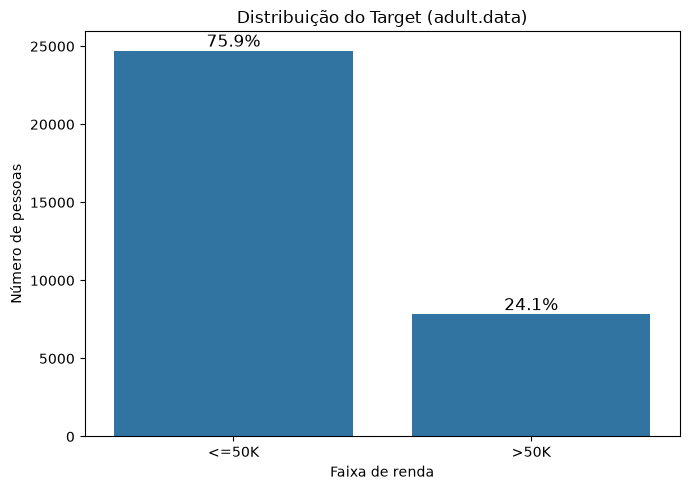

In [34]:

proporcoes = adult_data["Target"].value_counts(normalize=True)
print(proporcoes)

fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=adult_data, x="Target", order=["<=50K", ">50K"], ax=ax)

# porcentagem sobre cada barra
total = len(adult_data)
for barra in ax.patches:
    altura = barra.get_height()
    ax.annotate(f"{altura / total:.1%}",
                (barra.get_x() + barra.get_width() / 2, altura),
                ha="center", va="bottom", fontsize=12)

ax.set_title("Distribuição do Target (adult.data)")
ax.set_xlabel("Faixa de renda")
ax.set_ylabel("Número de pessoas")
plt.tight_layout()
plt.show()

**Conclusão.** As classes são desbalanceadas: cerca de 75,9% das pessoas ganham `<=50K` e apenas 24,1% ganham `>50K`. Isso significa que um modelo que prevesse sempre `<=50K` já acertaria cerca de 76%, então a acurácia do kNN deve ser lida contra essa linha de base. Além disso, a acurácia sozinha pode esconder um desempenho pior na classe minoritária (`>50K`), por isso mais adiante vamos analisar também a matriz de confusão e a revocação dessa classe.

In [ ]:
adult_data.isna().sum()

Age                  0
Workclass         1836
fnlwgt               0
Education            0
Education-Num        0
Martial Status       0
Occupation        1843
Relationship         0
Race                 0
Sex                  0
Capital Gain         0
Capital Loss         0
Hours per week       0
Country            583
Target               0
dtype: int64

In [ ]:
adult_clean = adult_data.dropna()
test_clean = adult_test.dropna()

In [ ]:
adult_clean.shape

(30162, 15)

In [ ]:
test_clean.shape

(15060, 15)

In [ ]:
adult_data_treinamento = adult_clean.drop(columns = "Target")
adult_data_resposta = adult_clean["Target"]
adult_test_avaliação = test_clean.drop(columns = "Target")
adult_test_resposta= test_clean["Target"]


In [ ]:
adult_data_treinamento.shape

(30162, 14)

In [ ]:
adult_data_resposta.shape

(30162,)

In [ ]:
adult_test_avaliação.shape

(15060, 14)

In [ ]:
adult_test_resposta.shape

(15060,)

In [ ]:
adult_data_treinamento.dtypes

Age               int64
Workclass           str
fnlwgt            int64
Education           str
Education-Num     int64
Martial Status      str
Occupation          str
Relationship        str
Race                str
Sex                 str
Capital Gain      int64
Capital Loss      int64
Hours per week    int64
Country             str
dtype: object

In [ ]:
preprocessador = ColumnTransformer([("final_numbers", StandardScaler(), colunas_numericas), ("final_categorics", OneHotEncoder(handle_unknown="ignore"), colunas_categoricas)])

In [ ]:
Xadult = preprocessador.fit_transform(adult_data_treinamento)
Xadult.shape

(30162, 104)

In [ ]:
model = [("prep", preprocessador), ("knn", KNeighborsClassifier(n_neighbors= 5))]
sleep = Pipeline(model)

In [ ]:
resultado_final = cross_val_score(sleep, adult_data_treinamento, adult_data_resposta, cv=5).mean()
print(resultado_final)

0.8283273835197308


In [ ]:
candidatos = [21, 25, 31, 35, 39, 40, 41, 42, 45, 51]
parametros = {"knn__n_neighbors": candidatos}
busca = GridSearchCV(sleep, parametros, cv=5, n_jobs = 2, verbose =2)

In [ ]:
busca.fit(adult_data_treinamento, adult_data_resposta)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__n_neighbors': [21, 25, ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection str

In [ ]:
print(busca.best_params_)
print(busca.best_score_)

{'knn__n_neighbors': 41}
0.839334626618145


In [ ]:
previsao = busca.predict(adult_test_avaliação)

In [ ]:
acuracia = accuracy_score(adult_test_resposta, previsao)
print(acuracia)

0.8389774236387783


In [ ]:
error = (1 - acuracia)
print(error)

0.16102257636122175


## Resultado do modelo base

**Configuração**
- Classificador: kNN, com pré-processamento em pipeline (padronização das variáveis numéricas e one-hot das categóricas).
- Tratamento de ausentes: linhas com valores faltantes foram descartadas, tanto no treino (30.162 linhas restantes) quanto no holdout (15.060 linhas restantes). É uma versão provisória, que será comparada depois com a imputação pela moda.
- Escolha de k: validação cruzada estratificada de 5 dobras, usando apenas o treino, com k ímpares para evitar empates na votação.

**Resultados**
- Melhor k: **41**, com acurácia média de validação de **0,8393**.
- Acurácia no holdout: **0,8390**.
- Erro empírico no holdout: **0,1610 (16,1%)**.

**Interpretação**
A acurácia no holdout ficou praticamente igual à da validação cruzada (diferença de cerca de 0,0003). Isso indica que o k escolhido generaliza bem para dados novos, sem sinal de ajuste excessivo ao treino. Com 15.060 exemplos, o erro-padrão da estimativa é de cerca de 0,3 ponto percentual, então o erro verdadeiro deve estar entre aproximadamente 15,5% e 16,7% (intervalo de 95%). Variações menores que isso entre versões do modelo estão dentro do ruído.

**Observação sobre a escolha de k**
Em buscas separadas, k=41 foi o melhor em duas listas diferentes de candidatos, e valores próximos (de 35 a 45) tiveram notas muito parecidas, o que mostra que a escolha é estável.

In [ ]:
identificador = kaggle_data["Id"]
Xkaggle_data = kaggle_data.drop(columns="Id")

In [ ]:
Xkaggle_data.columns = adult_data_treinamento.columns

In [ ]:
print( list(Xkaggle_data.columns) == list(adult_data_treinamento.columns))

True


In [ ]:
preprocessador_imp = ColumnTransformer([
    ("final_numbers_2", StandardScaler(), colunas_numericas)
    , ("final_categorics_2", Pipeline([
        ("imputador", SimpleImputer(strategy= "most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown = "ignore")),
        ]),colunas_categoricas),
])       

In [ ]:
pipeline_imp = Pipeline([
    ("prep", preprocessador_imp),
    ("knn", KNeighborsClassifier(n_neighbors=41)),
])

In [ ]:
# dados completos, sem descartar nenhuma linha
X_completo = adult_data.drop(columns="Target")
y_completo = adult_data["Target"]
print(X_completo.shape, y_completo.shape)   # esperado: (32561, 14) (32561,)


(32561, 14) (32561,)


In [ ]:
# treina e prevê o teste do Kaggle
pipeline_imp.fit(X_completo, y_completo)
previsao_kaggle = pipeline_imp.predict(Xkaggle_data)
print(len(previsao_kaggle))                 # esperado: 16280

16280


In [ ]:
# arquivo de entrega
submission = pd.DataFrame({"Id": identificador, "income": previsao_kaggle})
submission.to_csv("submission.csv", index=False)
print(submission.shape)                     # esperado: (16280, 2)
print(submission["income"].value_counts(normalize=True))

(16280, 2)
income
<=50K    0.797297
>50K     0.202703
Name: proportion, dtype: float64
